In [18]:
# import the necessary libraries
import math 
import numpy as np
import matplotlib.pyplot as plt
import random

In [19]:
random.seed(1234) # set the seed for automated marking (do not delete)

In [20]:

NAME = "JABIR HUSSAIN"

# A2 Nonreversible Markov processes

**Dr Michael Faulkner**

## IMPORTANT

1) Be sure to use the *Biochemistry* server in Noteable.  We believe that Noteable have fixed the bug that generates duplicated cells, but **only on this server**.
2) Students **should not** duplicate cells as duplicated cells are very difficult to manage during the marking process.  As such, duplicated cells **will not be considered** for marking.

## Submission

This is the second assignment of ES98D, worth 1.2 CATs in total.

Before you submit this assignment, make sure everything runs as expected. First, **restart the kernel** (in the menubar, select Kernel $\rightarrow$ Restart) and then **run all cells** (in the menubar, select Cell $\rightarrow$ Run All).

Make sure you fill in any place that says `YOUR CODE HERE` or "YOUR ANSWER HERE".

You should submit your completed notebook via the nbgrader interface.  Once finished, go back to the Assignments tab and click submit.  You can repeat this process if you are not happy with your original submission.  This submits a version of the notebook with all outputs cleared.  Please also subit an HTML version of your submission via Moodle (or via email to me and Albert if no link is available).

Feedback will be released through the nbgrader interface.  You will be able to download this from the Assignments tab.

## Overview

This assignment aims to deepen your understanding of nonreversible Markov processes - based on the lifted random walk and event-chain Monte Carlo (ECMC).

We concentrate on the following tasks:

1) Random Walk and lifted random walk
- Implement both the random walk and lifted random walk on a 1D lattice with boundaries.
- Test the correctness of each algorithm via their empirical means and empirical variances.
- Plot the trajectories generated by each algorithm.
- Compare performance. 

2) ECMC for a particle in a 1D quartic potential
- Write an algorithm to simulate Metropolis Monte Carlo for the model.
- Write an algorithm to simulate event-chain Monte Carlo for the model.
- Compare the CDFs (of the particle position) generated by each method.
- Compare performance.

## Part 1: Random walk and lifted random walk

As explained in the lecture, we can use either the random walk or the lifted random walk to sample from the discrete uniform distribution $\mathcal{U}(\{-N, -N + 1, \dots, N - 1, N\})$ for some integer $N > 0$.

### Part 1a: Random walk

We start by considering a random walk on a 1D lattice $\{-N, -N + 1, \dots, N - 1, N\}$ where $\pm N$ are the two boundary sites.  In the interior of the lattice, the random walk moves right/left ($x \mapsto x \pm 1$) with probability $1 / 2$; at the two boundary sites ($x = \pm N$), it stays still/moves to the only neighbouring site with probability $1 / 2$, as illustrated by the following diagram:

![image](random-walk.png)

**Question 1a:** Complete the get_random_walk_trajectory() function below [5 marks].

In [21]:
def get_random_walk_trajectory(no_of_steps, initial_state, boundary_magnitude, random_seed=None):
    r"""This function generates the trajectory x of a random walk on a one-dimensional lattice with boundaries at 
        x = +- boundary_magnitude.
        
        Parameters
        ----------
        no_of_steps : int
            The total number of steps in the random walk.
        initial_state : int
            The initial state/position x of the random walk.
        boundary_magnitude : int
            The magnitude of the state/position at the boundaries.
        random_seed : int
            The seed for the random number generator.  If None, the seed is automatically generated.

        Returns
        -------
        numpy.ndarray
            The generated trajectory.  A one-dimensional numpy array of length no_of_steps; each element is an 
            integer and represents one state in the trajectory.
    """
    if random_seed is not None:
        np.random.seed(random_seed)

    trajectory = np.empty(no_of_steps, dtype=int)
    trajectory[0] = initial_state

    for t in range(1, no_of_steps):
        sample = np.random.rand()
        if trajectory[t-1] == -boundary_magnitude:
            # boundary at -N: stay or move to -N+1 with prob 1/2 each
            trajectory[t] = -boundary_magnitude if sample < 0.5 else -boundary_magnitude + 1

        elif trajectory[t-1] == boundary_magnitude:
            # boundary at +N: stay or move to N-1 with prob 1/2 each
            trajectory[t] = boundary_magnitude if sample < 0.5 else boundary_magnitude - 1

        else:
            # interior: step left/right with prob 1/2 each
            trajectory[t] = trajectory[t-1] - 1 if sample < 0.5 else trajectory[t-1] + 1
            
    return np.array(trajectory)

Here we test your code by checking that the empirical mean and empirical variance of the generated trajectory are close to the target mean and target variance of $\mathcal{U}(-N, N)$.

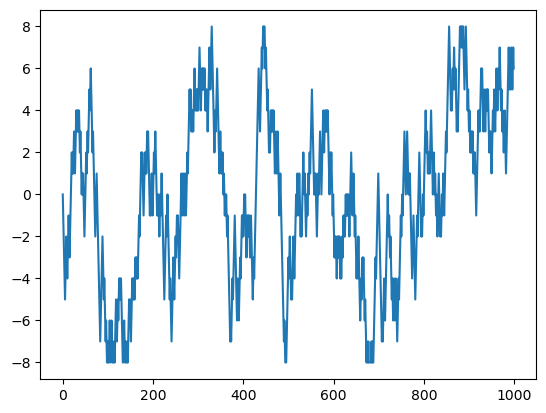

In [22]:
# Simulate the random walk 
no_of_steps = 10 ** 7
boundary_magnitude = 8
initial_state = 0
trajectory_random_walk = get_random_walk_trajectory(no_of_steps, initial_state, boundary_magnitude)
plt.plot(trajectory_random_walk[0:1000])

In [23]:
# Calculate the empirical mean and variance before testing them below
empirical_mean_random_walk = np.mean(trajectory_random_walk)
empirical_variance_random_walk = np.var(trajectory_random_walk)
target_variance = (boundary_magnitude * (boundary_magnitude + 1) / 3)

In [24]:
assert abs(empirical_mean_random_walk) < 0.05, \
    f"The empirical mean is {empirical_mean_random_walk} but the target mean is zero."

In [25]:
assert abs((empirical_variance_random_walk / target_variance - 1.0)) < 0.05, \
    f"The empirical variance is {empirical_variance_random_walk} but the target variance is {target_variance}."

### Part 1b: Lifted random walk

We now consider a lifted random walk on the same lattice $\{-N, -N + 1, \dots, N - 1, N\}$.  The lifted random walk has velocity $v = \pm 1$ at any given time.  In the interior of the lattice, it makes the move $x \mapsto x + v$ with probability $1 - r$, with $0 < r < 1$.  Otherwise, it stays still ($x \mapsto x$) and flips the velocity ($v \mapsto -v$).  As described in the lectures, you can equivalently think of this second step as the system staying still on the original state space, but transitioning to a second copy of that original state space - where the system advances in the negative/positive direction on the first/second copy with probability zero.  This is illustrated by the following diagram, which also illustrates the rules at the boundary sites:

![image](lifted-random-walk.png)

**Question 1b:** Complete the get_lifted_random_walk_trajectory() function below [8 marks].

In [26]:
def get_lifted_random_walk_trajectory(no_of_steps, initial_state, initial_velocity, boundary_magnitude, random_seed=None):
    r"""This function generates the trajectory x of a lifted random walk (with velocity = +-1) on a 
        one-dimensional lattice with boundaries at x = +- boundary_magnitude.
        
        Parameters
        ----------
        no_of_steps : int
            The total number of steps in the lifted random walk.
        initial_state : int
            The initial state/position x of the lifted random walk.
        initial_velocity : int
            The initial velocity of the lifted random walk (must be +1 or -1).
        boundary_magnitude : int
            The magnitude of the state/position at the boundaries.
        random_seed : int
            The seed for the random number generator.  If None, the seed is automatically generated.

        Returns
        -------
        numpy.ndarray
            The generated trajectory.  A one-dimensional numpy array of length no_of_steps; each element is an 
            integer and represents one state in the trajectory.

        Raises
        ------
        ValueError
            If initial_velocity does not equal plus or minus one.
            
    """
    if random_seed is not None:
        np.random.seed(random_seed)
    if abs(initial_velocity) != 1:
        raise ValueError(f"initial_velocity is {initial_velocity} but its magnitude must be one.")

    r = 1.0 / (2*boundary_magnitude + 1)
    
    trajectory = np.empty(no_of_steps, dtype=int)
    trajectory[0] = int(initial_state)

    velocity = int(initial_velocity)

    for t in range(1, no_of_steps):
        sample = np.random.rand()

        if sample < r:
            # flip velocity
            trajectory[t] = trajectory[t-1]
            velocity = -velocity

        else:
            proposed = trajectory[t-1] + velocity

            if proposed < -boundary_magnitude or proposed > boundary_magnitude:
                trajectory[t] = trajectory[t-1]
                velocity = -velocity

            else:
                trajectory[t] = proposed
                
    return np.array(trajectory)

As above, here we test your code by checking that the empirical mean and empirical variance of the generated state-space trajectory are close to the target mean and target variance of $\mathcal{U}(-N, N)$.

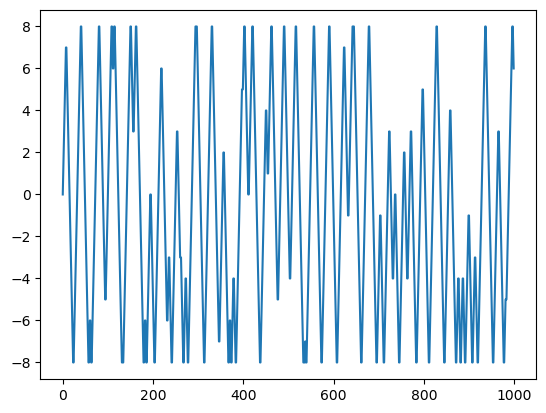

In [27]:
# Simulate the lifted random walk 
no_of_steps = 10 ** 6
boundary_magnitude = 8
initial_state = 0
initial_velocity =  1
trajectory_lifted_random_walk = get_lifted_random_walk_trajectory(no_of_steps, initial_state, initial_velocity, boundary_magnitude)
plt.plot(trajectory_lifted_random_walk[0:1000])

In [28]:
# Calculate the empirical mean and variance before testing them below
empirical_mean_lifted_random_walk = np.mean(trajectory_lifted_random_walk)
empirical_variance_lifted_random_walk = np.var(trajectory_lifted_random_walk)
target_variance = (boundary_magnitude * (boundary_magnitude + 1) / 3)

In [29]:
assert abs(empirical_mean_lifted_random_walk) < 0.05, \
    f"The empirical mean is {empirical_mean_lifted_random_walk} but the target mean is zero."

In [30]:
assert abs(empirical_variance_lifted_random_walk / target_variance - 1.0) < 0.05, \
    f"The empirical variance is {empirical_variance_lifted_random_walk} but the target variance is {target_variance}."

**Question 1c:** Using ideas (and code!) from the first assignment, create a plot that compares the quality of the samples generated by the two algorithms (for the parameters given below).  This plot should demonstrate (for each algorithm) how many Monte Carlo time steps the user should wait between IID samples.  The functions should be normalised such that they intercept the $y$-axis at $1$.  Also print a numerical value (in the legend of your figure) that quantifies this number of time steps. [5 marks]

Use both this plot and the numerical values to comment on the comparitive efficiency of the two algorithms. [20 marks]

(N.B. you may change the parameters while developing your code but you must reset them to the given values before submitting the assignment.)

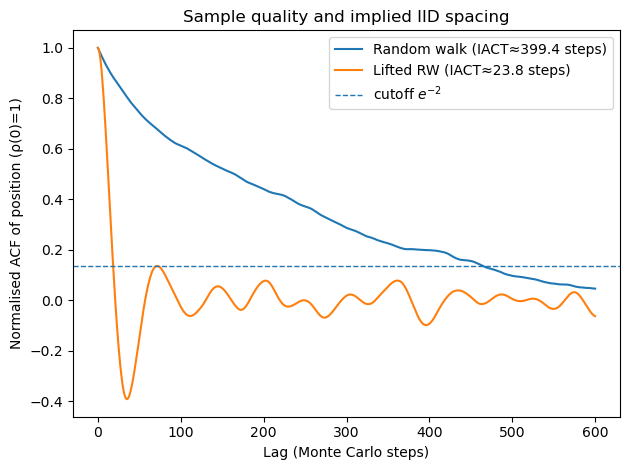

In [32]:
# Simulate both random walks
no_of_steps = 10 ** 4
boundary_magnitude = 16
initial_state = 0
initial_velocity = np.random.choice((-1, 1))
trajectory_random_walk = get_random_walk_trajectory(no_of_steps, initial_state, boundary_magnitude)
trajectory_lifted_random_walk = get_lifted_random_walk_trajectory(no_of_steps, initial_state, initial_velocity, boundary_magnitude)

def autocorr(x):
    x = np.asarray(x, dtype=float)
    x = x - x.mean()
    ac = np.correlate(x, x, mode="full")
    return ac[ac.size // 2:]

def normalised_ac(x, lag):
    ac = autocorr(x)[:lag + 1]
    return ac / ac[0]

def iact(rho, cutoff=math.e**(-2)):
    index = np.where(rho < cutoff)[0]
    if len(index) > 0:
        max_k = (index[0] - 1)
    else:
        max_k = len(rho) - 1

    return 2.0 * np.sum(rho[:max_k +1]) - 1.0

lag = 600
rho_rand_walk = normalised_ac(trajectory_random_walk, lag)
rho_lifted_rand_walk = normalised_ac(trajectory_lifted_random_walk, lag)
tau_rand_walk = iact(rho_rand_walk)
tau_lifted_rand_walk = iact(rho_lifted_rand_walk)

lags = np.arange(lag + 1)

plt.figure()
plt.plot(lags, rho_rand_walk, label=f"Random walk (IACT≈{tau_rand_walk:.1f} steps)")
plt.plot(lags, rho_lifted_rand_walk, label=f"Lifted RW (IACT≈{tau_lifted_rand_walk:.1f} steps)")
plt.axhline(math.e**(-2), linestyle="--", linewidth=1, label=r"cutoff $e^{-2}$")
plt.xlabel("Lag (Monte Carlo steps)")
plt.ylabel("Normalised ACF of position (ρ(0)=1)")
plt.title("Sample quality and implied IID spacing")
plt.legend()
plt.tight_layout()
plt.show()

For the random walk, the autocorrelation function decays very slowly, staying positive till around 450 Monte Carlo steps. This shows slow mixing and strong persistence. For the lifted random walk, the autocorrelation function drops and crosses zero sharply, oscillating around zero with small magnitude after. This shows stronger mixing and decorrelation, showing the chain losing memory faster.

The IACT approximates the number of MC steps between effectively independent samples. The random walk IACT is 399.4 and the lifted random walk IACT is 23.8, showing a 16.78x speed up in finding effectively independent samples. This is because the random walk revisits recent states whereas the lifted walk uses velocity to reduce backtracking, moving across the state space "faster". Having a smaller refresh rate prevents trapping, which aids faster mixing and in turn a smaller autocorrelation time.

## Part 2: Event-chain Monte Carlo for the 1D quartic potential

This second part of the assignment focusses on event-chain Monte Carlo - a continuous-space analogue of the lifted random walk.

As ECMC can be quite challenging to code in the first instance, our test case will be a single particle in a quartic potential on the real line.  The potential (energy) function is defined as
$$
U_\textrm{quartic}(x) = \frac{\varepsilon}{4} (x - x_{\rm min})^4 ,
$$
where $\varepsilon > 0$ is a constant with units of energy and $x_{\rm min} \in \mathbb{R}$ is the coordinate of the minimum of the potential.

### Part 2a: Metropolis Monte Carlo

We start by simulating the model with the Metropolis algorithm, to provide ourselves with a base case against which to measure performance.

**Question 2a (i):** Complete the function `get_potential()` below [2 marks]

In [33]:
def get_potential(config, epsilon, min_position):
    r"""
    Returns the potential energy of the 1D quartic model for the given particle configuration.

    Parameters
    ----------
    config : float
        The current particle position.
    epsilon : float
        The constant with units of energy.
    min_position : float
        The position of the minimum of the potential.

    Returns
    -------
    float
        The potential energy.
    """
    # YOUR CODE HERE
    return (epsilon / 4.0) * (config - min_position) ** 4


def get_potential_difference(config, candidate_position, epsilon, min_position):
    r"""
    Returns the potential difference (of the 1D quartic model) resulting from moving the single active 
        particle to candidate_position.

    Parameters
    ----------
    config : float
        The current particle position.
    candidate_position : float
        The candidate particle position.
    epsilon : float
        The constant with units of energy.
    min_position : float
        The position of the minimum of the potential.

    Returns
    -------
    float
        The potential difference resulting from moving the single active particle to candidate_position.
    """
    return get_potential(candidate_position, epsilon, min_position) - get_potential(config, epsilon, min_position)

Here we test your ```get_potential()``` function.

In [34]:
config = 2.78349
min_position = 2.0
epsilon = 7.34
target_potential = 0.691464518210
potential = get_potential(config, epsilon, min_position)
assert abs(potential / target_potential - 1.0) < 0.00001, \
        (f"get_potential() acting on configuration {config} returns {potential} but it should return {target_potential}.")

In [35]:
config = -3.78349
min_position = 5.0
epsilon = 2.163
target_potential = 3218.584925259
potential = get_potential(config, epsilon, min_position)
assert abs(potential / target_potential - 1.0) < 0.00001, \
        (f"get_potential() acting on configuration {config} returns {potential} but it should return {target_potential}.")

In [36]:
config = -1.38219
min_position = -1.8
epsilon = 0.24536
target_potential = 0.00186921429167
potential = get_potential(config, epsilon, min_position)
assert abs(potential / target_potential - 1.0) < 0.00001, \
        (f"get_potential() acting on configuration {config} returns {potential} but it should return {target_potential}.")

In [37]:
config = 8.8148
min_position = 6.809
epsilon = 1.33689
target_potential = 5.40986205594
potential = get_potential(config, epsilon, min_position)
assert abs(potential / target_potential - 1.0) < 0.00001, \
        (f"get_potential() acting on configuration {config} returns {potential} but it should return {target_potential}.")

**Question 2a (ii):** Complete the function `get_metropolis_trajectory()` such that it generates a Metropolis Monte Carlo trajectory of the 1D quartic model for the given inputs [5 marks]

In [38]:
def get_metropolis_trajectory(initial_config, temperature, epsilon, min_position, no_of_burn_in_steps, 
                              no_of_samples, width_of_noise_distribution):
    r"""This function generates a single trajectory of a Metropolis MC simulation of the 1D quartic model.
        
        Parameters
        ----------
        initial_config : float
            The initial particle position.
        temperature : float
            The sampling temperature (per unit Boltzmann constant).
        epsilon : float
            The constant with units of energy.
        min_position : float
            The position of the minimum of the potential.
        no_of_burn_in_steps : int
            The total number of burn-in iterations before sampling begins.
        no_of_samples : int
            The total number of equilibrated samples to be generated.
        width_of_noise_distribution : float
            The width of the uniform noise distribution used to propose particle displacements.

        Returns
        -------
        numpy.ndarray
            The generated trajectory.  A two-dimensional numpy array of shape (2, no_of_burn_in_steps + no_of_samples); 
            element (0 / 1, i) is a float representing the potential / position at Monte Carlo iteration i.
    """
    config = initial_config
    no_of_mc_sweeps = no_of_burn_in_steps + no_of_samples
    no_of_accepted_metrop_proposals = 0
    potential_trajectory = []
    position_trajectory = []

    for sweep in range(no_of_mc_sweeps):
        proposal = config + np.random.uniform(
            -width_of_noise_distribution,
            width_of_noise_distribution
        )

        delta_U = get_potential_difference(
            config,
            proposal,
            epsilon,
            min_position
        )

        if delta_U <= 0 or np.random.rand() < np.exp(-delta_U / temperature):
            config = proposal
            if sweep >= no_of_burn_in_steps:
                no_of_accepted_metrop_proposals += 1

        if sweep >= no_of_burn_in_steps:
            potential_trajectory.append(
                get_potential(config, epsilon, min_position)
            )
            position_trajectory.append(config)
            
    print(f"Metropolis acceptance rate = {no_of_accepted_metrop_proposals / no_of_samples}.")
    return np.array([potential_trajectory, position_trajectory])

Here we test your code by checking that its empirical cumulative distribution function (for the particle position) agrees with a reference sample.  To do this, we provide a function that transforms a 1D sample to an empircial cumulative distribution function.

In [39]:
def get_cumulative_distribution(one_dimensional_sample):
    if len(np.atleast_2d(one_dimensional_sample)) > 1:
        raise Exception("Error: the sample passed to markov_chain_diagnostics.get_cumulative_distribution() must be "
                        "one (Cartesian) dimensional.")
    bin_values = np.arange(1, len(one_dimensional_sample) + 1) / float(len(one_dimensional_sample))
    ordered_sample = np.sort(one_dimensional_sample)
    return [ordered_sample, bin_values]

Metropolis acceptance rate = 0.24345.


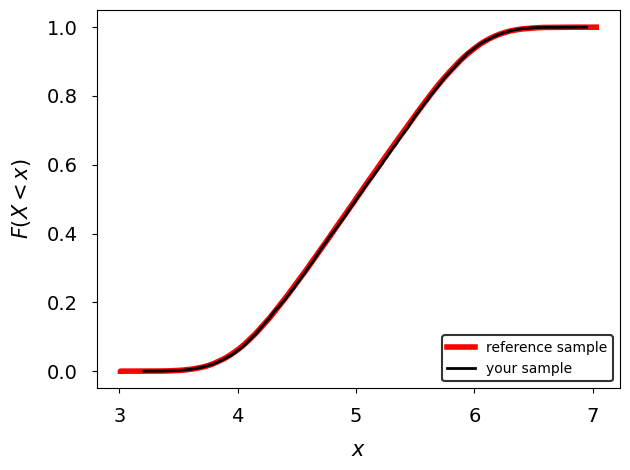

In [40]:
temperature = 1.0
epsilon = 2.5
min_position = 5.0
initial_config = np.random.normal() # generates a random initial configuration
no_of_burn_in_steps = 1000
no_of_samples = 100000
width_of_noise_distribution = 4.5

reference_sample = np.load("quartic_model_shifted_right_reference_sample.npy")
reference_cdf = get_cumulative_distribution(reference_sample)

metropolis_trajectory = get_metropolis_trajectory(initial_config, temperature, epsilon, min_position, 
                                                  no_of_burn_in_steps, no_of_samples, width_of_noise_distribution)
metrop_position_sample = metropolis_trajectory[1, no_of_burn_in_steps:]
metrop_position_sample_cdf = get_cumulative_distribution(metrop_position_sample)

plt.plot(reference_cdf[0], reference_cdf[1], color='r', linewidth=4, linestyle='-', label='reference sample')
plt.plot(metrop_position_sample_cdf[0], metrop_position_sample_cdf[1], color='k', linewidth=2, linestyle='-', label='your sample')

plt.xlabel(r"$x$", fontsize=15, labelpad=10)
plt.ylabel(r"$ F \left( X < x \right)$", fontsize=15, labelpad=10)
plt.tick_params(axis='both', which='major', labelsize=14, pad=10)
legend = plt.legend(loc='lower right', fontsize=10)
legend.get_frame().set_edgecolor('k')
legend.get_frame().set_lw(1.5)
plt.tight_layout()
plt.show()

Metropolis acceptance rate = 0.25984.


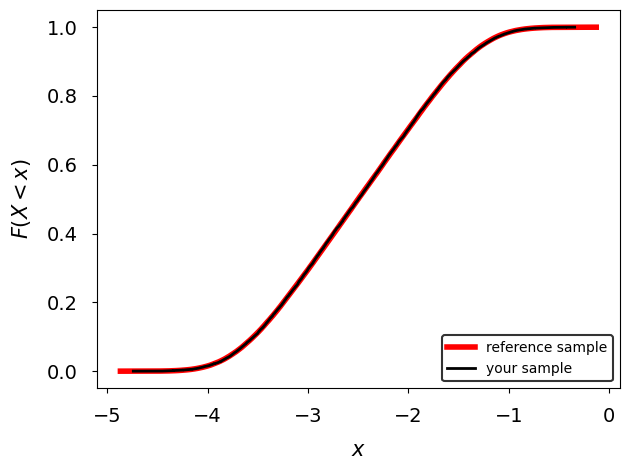

In [41]:
temperature = 1.0
epsilon = 1.25
min_position = -2.5
initial_config = np.random.normal() # generates a random initial configuration
no_of_burn_in_steps = 1000
no_of_samples = 100000
width_of_noise_distribution = 5.0

reference_sample = np.load("quartic_model_shifted_left_reference_sample.npy")
reference_cdf = get_cumulative_distribution(reference_sample)

metropolis_trajectory = get_metropolis_trajectory(initial_config, temperature, epsilon, min_position, 
                                                  no_of_burn_in_steps, no_of_samples, width_of_noise_distribution)
metrop_position_sample = metropolis_trajectory[1, no_of_burn_in_steps:]
metrop_position_sample_cdf = get_cumulative_distribution(metrop_position_sample)

plt.plot(reference_cdf[0], reference_cdf[1], color='r', linewidth=4, linestyle='-', label='reference sample')
plt.plot(metrop_position_sample_cdf[0], metrop_position_sample_cdf[1], color='k', linewidth=2, linestyle='-', label='your sample')

plt.xlabel(r"$x$", fontsize=15, labelpad=10)
plt.ylabel(r"$ F \left( X < x \right)$", fontsize=15, labelpad=10)
plt.tick_params(axis='both', which='major', labelsize=14, pad=10)
legend = plt.legend(loc='lower right', fontsize=10)
legend.get_frame().set_edgecolor('k')
legend.get_frame().set_lw(1.5)
plt.tight_layout()
plt.show()

### Part 2b: Event rate and distance to event

At any given Monte Carlo time $t_0 > 0$, ECMC continuously advances the particle at some velocity $v = \pm 1$ until the next event time $t_0 + \tau_\eta$, at which point an event occurs ($\tau_\eta > 0$).  This event pauses the dynamics and the velocity is reversed.  The simulation then restarts from the same configuration $x$ but with the new velocity, resulting in motion in the opposite direction.

This is analogous to the picture described in the lectures.  Here, we described translationally invariant $N$-particle models on the torus - in which a single active particle advances until an event occurs, after which another particle takes over and continues in the same direction.  The difference here is that our model is of a single particle on the entire real line $\mathbb{R}$, i.e. a state space without toroidal topology.  This absence of periodicity (to the state space) means that we have to bounce at events.

In addition, the process also stops periodically to uniformly resample the velocity.  At another independent (sampling) time, it also stops to record the particle position (though to simplify things, one can choose to do both at the same time, as we do below).

The distribution of the next event time $\tau_\eta$ is governed by a nonhomogenous Poisson process:
$$
\mathbb{P}(\tau_\eta > t) = \exp\left(- \int_{0}^{t} \lambda(s) ds \right) ,
$$
where 
$$
\lambda(t) := \beta \max \left[0, v \left. \frac{dU_\textrm{quartic}}{dx'} \right|_{x' = x + vt} \right] 
$$
is the event rate for the quartic potential $U_\textrm{quartic}$ at position $x$ and velocity $v$.  This presents the material from the lectures more formally, but the key result is that sampling $\tau_\eta$ at each iteration of the algorithm corresponds to solving the ECMC master equation from the lectures:
$$
\Upsilon = \exp\left(- \int_{0}^{\tau_\eta} \lambda(s) ds \right) ,
$$
where $\Upsilon \sim \mathrm{Unif}(0, 1)$ is some uniformly distributed random number on $(0, 1)$, which we sample at each iteration of the algorithm.  As discussed in the lectures, $- \ln \Upsilon / \beta$ is then the *uphill energy* - which the process uses to advance the particle through the uphill parts of the potential.  The event corresponds to the first time at which the uphill energy has all been used.

**Question 2b (i):** With $\eta > 0$ defined as the distance travelled through state space until the next event occurs, re-express the ECMC master equation in position space and in terms of $dU_\textrm{quartic} / dx$.  Following this, derive the event rate for the 1D quartic model then re-write the master equation in terms of this function [10 marks].

Comment on why the process stops to record the particle position at independent times, rather than recording the position at each event. [5 marks]

At MC time $t_0$, position $x \in \mathbb{R}$ and velocity $v \in {-1, 1}$, the PDMP is deterministic between events $$x(t) = x + vt, \quad t \ge 0.$$

Using a non-homogenous Poisson process, we generate events using the survival function $$\mathbb{P}( \tau_n > t) = \exp \left ( - \int_0^t \lambda(s) ds \right ).$$

By sampling $\Upsilon \sim U(0,1)$, we have the ECMC master equation 

$$\Upsilon = \exp \left ( - \int_0^{t} \lambda(s) ds \right) \Longleftrightarrow -\ln\Upsilon = \int_0^{\tau_{\eta}} \lambda(s) ds $$

We know that the event rate is given by $$\lambda(t) := \beta\max\left \{ 0, v\frac{dU}{dx} \mid_{x' = x+vt} \right \}.$$

With $|v| = 1$, the time travelled is equal to the distance travelled, thus $\eta = \tau_{\eta}$, giving the master equation $$-\ln \Upsilon = \beta \int_0^{\eta}\max \left \{ 0, v\frac{dU}{dx}(x+vs) \right \} ds.$$

Since $U_{quartic}(x) = \frac{\epsilon}{4}(x-x_{\min})^4$, the derivative is $$\frac{dU_{\text{quartic}}}{dx}(x)=\epsilon(x-x_{\min})^3.$$

Substituting this into the general rate definition yields $$\lambda(t) = \beta\max\left \{ 0, v \in (x+vt-x_{\min})^3 \right \}.$$ Thus, the master equation for $\eta$ is $$-\ln \Upsilon = \beta \int_0^{\eta} \max \left \{ 0, v \in (x+vs-x_{\min})^3 \right \} ds $$

We record at independent times rather than event times since event times are dependent on state. For uphill regions where $vU'(x)$ is large and positive, the event rate is larger. Sampling for each event biases the distribution towards larger $\lambda$ regions. 

**Question 2b (ii):** Complete the following Python functions for the distance $\eta$ to the next event.  Be sure to account for the $\max (0, \cdot)$ function. [10 marks]

In [53]:
def get_distance_to_next_event(config, velocity, temperature, epsilon, min_position, random_number=None):
    r"""For the 1D quartic model, this function computes the distance to the next event.
        
        Parameters
        ----------
        config : float
            The current particle position.
        velocity : int
            The current system velocity.
        temperature : float
            The sampling temperature (per unit Boltzmann constant).
        epsilon : float
            The constant with units of energy.
        min_position : float
            The position of the minimum of the potential.
        random_number : float or None, optional
            A random_number on the interval (0, 1]. If not provided, it is generated below.

        Returns
        -------
            A float.  The displacement distance to the next event time.
    """
    if random_number is None:
        # np.random.rand() \in [0, 1) so we take 1.0 - np.random.rand() to avoid ln(0.0) infinities below
        random_number = 1.0 - np.random.rand()
    elif ((random_number <= 0.0) or (random_number > 1.0)):
        raise ValueError(f"random_number is {random_number} but it must a float on the interval [0, 1).")
        
    vz = velocity * (config - min_position)

    u = max(0.0, vz)
    energy = -temperature * np.log(random_number)

    distance = (u**4 + (4.0 * energy) / epsilon) ** 0.25 + max(0.0, -vz)
    return distance

Here we test your ```get_distance_to_next_event()``` function.

In [54]:
config = 2.78349
min_position = 2.0
epsilon = 7.34
velocity = 1
temperature = 1.0
target_distance_to_next_event = 0.9320151717114656
distance_to_next_event = get_distance_to_next_event(config, velocity, temperature, epsilon, min_position, 0.5)
assert abs(distance_to_next_event / target_distance_to_next_event - 1.0) < 0.00001, \
        (f"get_distance_to_next_event() acting on configuration {config} and velocity {velocity} (with random_number = 0.5) "
         f"returns {distance_to_next_event} but it should return {target_distance_to_next_event}.")

In [55]:
config = -3.78349
min_position = 5.0
epsilon = 2.163
velocity = -1
temperature = 1.0
target_distance_to_next_event = 8.78396285996
distance_to_next_event = get_distance_to_next_event(config, velocity, temperature, epsilon, min_position, 0.5)
assert abs(distance_to_next_event / target_distance_to_next_event - 1.0) < 0.00001, \
        (f"get_distance_to_next_event() acting on configuration {config} and velocity {velocity} (with random_number = 0.5) "
         f"returns {distance_to_next_event} but it should return {target_distance_to_next_event}.")

In [56]:
config = -1.38219
min_position = -1.8
epsilon = 0.24536
velocity = 1
temperature = 1.0
target_distance_to_next_event = 1.83469053054
distance_to_next_event = get_distance_to_next_event(config, velocity, temperature, epsilon, min_position, 0.5)
assert abs(distance_to_next_event / target_distance_to_next_event - 1.0) < 0.00001, \
        (f"get_distance_to_next_event() acting on configuration {config} and velocity {velocity} (with random_number = 0.5) "
         f"returns {distance_to_next_event} but it should return {target_distance_to_next_event}.")

In [57]:
config = 8.8148
min_position = 6.809
epsilon = 1.33689
velocity = -1
temperature = 1.0
target_distance_to_next_event = 3.20584475855
distance_to_next_event = get_distance_to_next_event(config, velocity, temperature, epsilon, min_position, 0.5)
assert abs(distance_to_next_event / target_distance_to_next_event - 1.0) < 0.00001, \
        (f"get_distance_to_next_event() acting on configuration {config} and velocity {velocity} (with random_number = 0.5) "
         f"returns {distance_to_next_event} but it should return {target_distance_to_next_event}.")

In [58]:
config = -12.87342345
min_position = 0.0
epsilon = 1.0
velocity = -1
temperature = 1.0
target_distance_to_next_event = 12.8737483329
distance_to_next_event = get_distance_to_next_event(config, velocity, temperature, epsilon, min_position, 0.5)
assert abs(distance_to_next_event / target_distance_to_next_event - 1.0) < 0.00001, \
        (f"get_distance_to_next_event() acting on configuration {config} and velocity {velocity} (with random_number = 0.5) "
         f"returns {distance_to_next_event} but it should return {target_distance_to_next_event}.")

### Part 2c: Event-chain Monte Carlo simulations

We now write an event-chain Monte Carlo algorithm for the model.

**Question 2c (i):** Complete the function `get_event_chain_trajectory()` such that it generates an event-chain Monte Carlo trajectory of the 1D quartic model for the given inputs [10 marks]

In [59]:
def get_event_chain_trajectory(initial_config, temperature, epsilon, min_position, no_of_burn_in_steps, 
                               no_of_samples, distance_between_samples):
    r"""This function generates a single trajectory of an event-chain simulation of the 1D quartic model.
        
        Parameters
        ----------
        initial_config : float
            The initial particle position.
        temperature : float
            The sampling temperature (per unit Boltzmann constant).
        epsilon : float
            The constant with units of energy.
        min_position : float
            The position of the minimum of the potential.
        no_of_burn_in_steps : int
            The total number of burn-in iterations before sampling begins.
        no_of_samples : int
            The total number of equilibrated samples to be generated.
        distance_between_samples : float
            Aggregate distance travelled through state space between samples.

        Returns
        -------
        The generated trajectory.  A two-dimensional numpy array of shape (2, no_of_burn_in_steps + no_of_samples); 
            element (0 / 1, i) is a float representing the potential / position at Monte Carlo iteration i.
    """
    config = initial_config
    no_of_mc_iterations = no_of_burn_in_steps + no_of_samples
    no_of_events = 0
    potential_trajectory = []
    position_trajectory = []

    for _ in range(no_of_mc_iterations):
        # for simplicity, we simultaneously draw a sample and uniformly resample the active particle and direction of motion
        velocity = np.random.choice((-1, 1))
        distance_to_next_sample = distance_between_samples
        while distance_to_next_sample > 0.0:
            distance_to_next_event = get_distance_to_next_event(
                config=config,
                velocity=velocity,
                temperature=temperature,
                epsilon=epsilon,
                min_position=min_position
            )

            if distance_to_next_event >= distance_to_next_sample:
                config += velocity * distance_to_next_sample
                distance_to_next_sample = 0.0

            else:
                config += velocity * distance_to_next_event
                distance_to_next_sample -= distance_to_next_event
                velocity = -velocity
                no_of_events += 1

        if _ >= no_of_burn_in_steps:
            potential_trajectory.append(get_potential(config, epsilon, min_position))
            position_trajectory.append(config)
            
    return np.array([potential_trajectory, position_trajectory])

We similarly test your event-chain code by checking that its empirical cumulative distribution function (for the particle position) agrees with a reference sample.

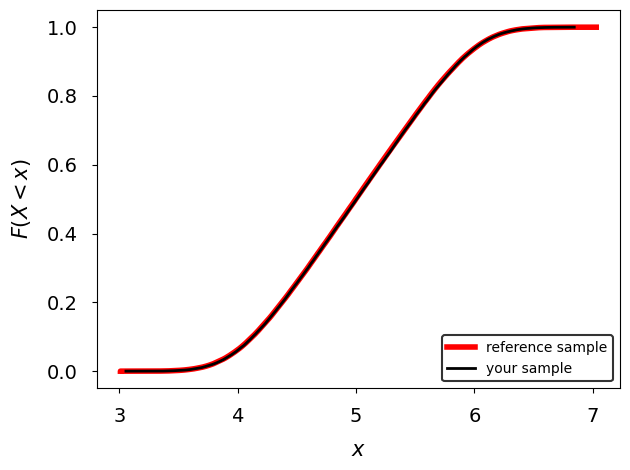

In [60]:
temperature = 1.0
epsilon = 2.5
min_position = 5.0
initial_config = np.random.normal() # generates a random initial configuration
no_of_burn_in_steps = 1000
no_of_samples = 100000
distance_between_samples = 10.0

reference_sample = np.load("quartic_model_shifted_right_reference_sample.npy")
reference_cdf = get_cumulative_distribution(reference_sample)

event_chain_trajectory = get_event_chain_trajectory(initial_config, temperature, epsilon, min_position, 
                                                    no_of_burn_in_steps, no_of_samples, distance_between_samples)
event_chain_position_sample = event_chain_trajectory[1, no_of_burn_in_steps:]
event_chain_position_sample_cdf = get_cumulative_distribution(event_chain_position_sample)

plt.plot(reference_cdf[0], reference_cdf[1], color='r', linewidth=4, linestyle='-', label='reference sample')
plt.plot(event_chain_position_sample_cdf[0], event_chain_position_sample_cdf[1], color='k', linewidth=2, linestyle='-', label='your sample')

plt.xlabel(r"$x$", fontsize=15, labelpad=10)
plt.ylabel(r"$ F \left( X < x \right)$", fontsize=15, labelpad=10)
plt.tick_params(axis='both', which='major', labelsize=14, pad=10)
legend = plt.legend(loc='lower right', fontsize=10)
legend.get_frame().set_edgecolor('k')
legend.get_frame().set_lw(1.5)
plt.tight_layout()
plt.show()

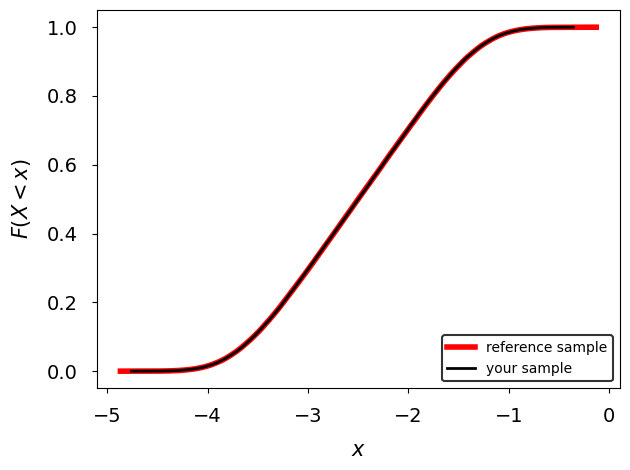

In [61]:
temperature = 1.0
epsilon = 1.25
min_position = -2.5
initial_config = np.random.normal() # generates a random initial configuration
no_of_burn_in_steps = 1000
no_of_samples = 100000
distance_between_samples = 10.0

reference_sample = np.load("quartic_model_shifted_left_reference_sample.npy")
reference_cdf = get_cumulative_distribution(reference_sample)

event_chain_trajectory = get_event_chain_trajectory(initial_config, temperature, epsilon, min_position, 
                                                    no_of_burn_in_steps, no_of_samples, distance_between_samples)
event_chain_position_sample = event_chain_trajectory[1, no_of_burn_in_steps:]
event_chain_position_sample_cdf = get_cumulative_distribution(event_chain_position_sample)

plt.plot(reference_cdf[0], reference_cdf[1], color='r', linewidth=4, linestyle='-', label='reference sample')
plt.plot(event_chain_position_sample_cdf[0], event_chain_position_sample_cdf[1], color='k', linewidth=2, linestyle='-', 
         label='your sample')

plt.xlabel(r"$x$", fontsize=15, labelpad=10)
plt.ylabel(r"$ F \left( X < x \right)$", fontsize=15, labelpad=10)
plt.tick_params(axis='both', which='major', labelsize=14, pad=10)
legend = plt.legend(loc='lower right', fontsize=10)
legend.get_frame().set_edgecolor('k')
legend.get_frame().set_lw(1.5)
plt.tight_layout()
plt.show()

**Question 2c (ii):** Repeat the process of Question 1c, making analogous comments. [3 marks (figure) + 12 marks (comments)]

In addition, test a few different ```width_of_metrop_noise_distribution``` values.  Comment on how much Metropolis sampling performance can be improved (or not) and whether event-chain efficiency can be reached.  **Be sure** to revert to the original parameters before submitting the assignment.  [5 marks]


Metropolis acceptance rate = 0.0751.


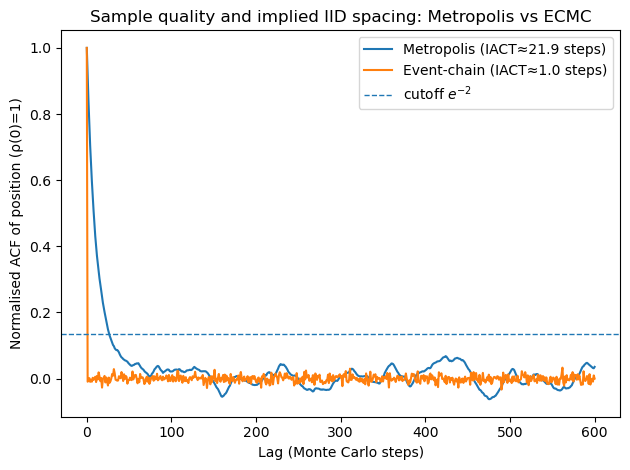

Metropolis acceptance rate = 0.8313.
width= 0.5 -> IACT≈   11.20
Metropolis acceptance rate = 0.6529.
width= 1.0 -> IACT≈    4.01
Metropolis acceptance rate = 0.2961.
width= 2.5 -> IACT≈    4.22
Metropolis acceptance rate = 0.1562.
width= 5.0 -> IACT≈    9.28
Metropolis acceptance rate = 0.0761.
width=10.0 -> IACT≈   22.98


In [65]:
# Simulate both algorithms
temperature = 1.0
epsilon = 10.0
min_position = -2.5
initial_config = np.random.normal() # generates a random initial configuration
no_of_burn_in_steps = 1000
no_of_samples = 10000
# width_of_metrop_noise_distribution = 2.5
width_of_metrop_noise_distribution = 10.0
distance_between_event_chain_samples = 10.0

metrop_trajectory = get_metropolis_trajectory(initial_config, temperature, epsilon, min_position, no_of_burn_in_steps, 
                                              no_of_samples, width_of_metrop_noise_distribution)
event_chain_trajectory = get_event_chain_trajectory(initial_config, temperature, epsilon, min_position, 
                                                    no_of_burn_in_steps, no_of_samples, distance_between_samples)
metrop_position_sample = metrop_trajectory[1, no_of_burn_in_steps:]
event_chain_position_sample = event_chain_trajectory[1, no_of_burn_in_steps:]

metropolis_rho = normalised_ac(metrop_position_sample, lag)
ecmc_rho = normalised_ac(event_chain_position_sample, lag)
metropolis_tau = iact(metropolis_rho)
ecmc_tau = iact(ecmc_rho)

plt.figure()
plt.plot(lags, metropolis_rho, label=f"Metropolis (IACT≈{metropolis_tau:.1f} steps)")
plt.plot(lags, ecmc_rho,   label=f"Event-chain (IACT≈{ecmc_tau:.1f} steps)")
plt.axhline(math.e**(-2), linestyle="--", linewidth=1, label=r"cutoff $e^{-2}$")
plt.xlabel("Lag (Monte Carlo steps)")
plt.ylabel("Normalised ACF of position (ρ(0)=1)")
plt.title("Sample quality and implied IID spacing: Metropolis vs ECMC")
plt.legend()
plt.tight_layout()
plt.show()

# different metrop noise dist widths
widths = [0.5, 1.0, 2.5, 5.0, 10.0]
for width in widths:
    metrop_traj_width = get_metropolis_trajectory(
        initial_config, temperature, epsilon, min_position,
        no_of_burn_in_steps, no_of_samples, width
    )
    sample_width = metrop_traj_width[1, no_of_burn_in_steps:]
    tau_width = iact(normalised_ac(sample_width, lag))
    print(f"width={width:>4} -> IACT≈{tau_width:>8.2f}")

For the original Metropolis width, it has a very low acceptance rate (0.0751) with a large IACT, showing high correlation between samples and little exploration across the chain. The smallest proposal width (0.5) had the highest metropolis acceptance rate (0.8313), however the moves are extremely localised so the chain decorrelates slowly. 

Metropolis still doesn't have the efficiency of ECMC which has an IACT of 1 step, meaning nearly every sample is independent! This is due to the dynamics of each algorithm: ECMC's ballistic motion offers much faster decorrelation as opposed to the diffusive approach Metropolis takes.